# Model 3: ResNet-18 CNN on Mel Spectrograms
Matthew Thomas · DATASCI 207

### Objective
Build a ResNet-18 CNN to predict the eight FMA genres from mel spectrograms. Compare final validation accuracy, macro-F1, and the training-validation accuracy gap from the original ResNet-18 model against hyperparameter fine-tuning as well as a model trained on 3-second audio windows.

### Data
Use the split CSVs in `data/tracked/` along with `data/local/mel_compact.npz`. The data split is 6,393 training, 800 validation, and 800 test tracks.

### References
ResNet architecture: [He et al., Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385)
3-Second Split Approach Influence: [Adibfar, O., Alavi, S.E. & Tahan, M.N. Music genre classification using spectrogram images and a lightweight efficientnet-based CNN](https://doi.org/10.1007/s11042-026-21923-1)

### Step 1: Import libraries and define configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Set repository paths 
REPO_ROOT = Path('.').resolve() if (Path('.').resolve() / 'data').exists() else Path('..').resolve()
LOCAL = REPO_ROOT / 'data/local'
TRACKED = REPO_ROOT / 'data/tracked'

# Set training settings
SEED = 207
MAX_EPOCHS = 40
PATIENCE = 8

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| Devices:', tf.config.list_physical_devices())

TensorFlow: 2.22.0-rc0 | Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### Step 2: Data ingestion & Split Verification
Loading the split data and genre mapping, running missing labels and artist overlap checks (also covered in previous WBs), and loading training and validation spectrograms for model development.

In [2]:
# Load the split metadata and genre mapping
tables = {}
for split in ['train', 'val', 'test']:
    tables[split] = pd.read_csv(TRACKED / f'{split}_mel.csv', index_col='track_id')

mapping = pd.read_csv(TRACKED / 'genre_mapping.csv').sort_values('genre_id')
class_names = mapping['genre'].tolist()
N_CLASSES = len(class_names)

# Confirm zero artist overlap across splits
train_artists = set(tables['train']['artist_id'])
val_artists = set(tables['val']['artist_id'])
test_artists = set(tables['test']['artist_id'])
print('Artist overlap (train/val, train/test, val/test):',
      len(train_artists & val_artists),
      len(train_artists & test_artists),
      len(val_artists & test_artists))

# Locate compact cache or fall back to processed_mel/
CACHE = LOCAL / 'mel_compact.npz'
COMPACT = CACHE.is_file()
if not COMPACT:
    CACHE = LOCAL / 'splits.npz'

FROM_NPY = not CACHE.is_file()
if FROM_NPY:
    CACHE = LOCAL / 'processed_mel'
    COMPACT = True
    print('Compact archive not found; pooling directly from processed_mel/*.npy')

def load_split(split):
    """Load one split of 128x128 pooled spectrograms and genre labels."""
    df = tables[split]
    if FROM_NPY:
        X = np.empty((len(df), 128, 128), dtype=np.float16)
        for i, track_id in enumerate(df.index):
            mel = np.load(CACHE / f'{int(track_id):06d}.npy').astype(np.float32)
            X[i] = mel[:, :1280].reshape(128, 128, 10).mean(axis=2)
        y = df['genre_id'].to_numpy()
    else:
        data = np.load(CACHE)
        X = data[f'X_{split}'] if COMPACT else data[f'Xf_{split}']
        y = data[f'y_{split}']
    X = X.reshape(len(df), 128, 128)
    return X, y.astype(np.int64)

X_train, y_train = load_split('train')
X_val, y_val = load_split('val')

print('Cache source:', CACHE.name)
print('X_train:', X_train.shape, '| X_val:', X_val.shape)
print('Value range:', round(float(X_train.min()), 2), 'to', round(float(X_train.max()), 2))
print('Classes:', class_names)

Artist overlap (train/val, train/test, val/test): 0 0 0
Compact archive not found; pooling directly from processed_mel/*.npy
Cache source: processed_mel
X_train: (6393, 128, 128) | X_val: (800, 128, 128)
Value range: -80.0 to -0.06
Classes: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']


### Step 3: Build ResNet-18 Model
Build and compile initial ResNet-18 model. ResNet-18 is an 18-layer CNN using a residual learning framework that use learning residual functions with reference to the layer inputs. It uses skip (shortcut) connections that add a block's input directly to its output, helping gradients flow smoothly. Each layer is built from basic blocks that contain two 3 × 3 convolution layers, batch normalization, ReLu activations, and a skip connection.

In [3]:
def build_model(learning_rate=0.001, dropout=0.3, l2=0.0001, input_shape=(128, 128, 1)):
    """Build and compile a ResNet-18 for eight-class genre prediction
    Args:
        learning_rate: Learning rate for the Adam optimizer
        dropout: Dropout rate before the output layer
        l2: L2 penalty applied to convolution and dense weights
    Returns:
        model: A compiled tf.keras model with eight output logits
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    regularizer = tf.keras.regularizers.l2(l2)

    # Define a convolution without bias because batch normalization follows it
    def conv_layer(x, filters, kernel_size, strides=1):
        return tf.keras.layers.Conv2D(
            filters=filters,
            kernel_size=kernel_size,
            strides=strides,
            padding='same',
            use_bias=False,
            kernel_initializer='he_normal',
            kernel_regularizer=regularizer
        )(x)

    # Add the learned transformation to the shortcut connection
    def residual_block(x, filters, strides):
        shortcut = x

        # First convolution, batch normalization, and activation
        output = conv_layer(x, filters, kernel_size=3, strides=strides)
        output = tf.keras.layers.BatchNormalization()(output)
        output = tf.keras.layers.ReLU()(output)

        # Second convolution and batch normalization
        output = conv_layer(output, filters, kernel_size=3)
        output = tf.keras.layers.BatchNormalization()(output)

        # Match dimensions when the block changes spatial size or channel count
        if strides != 1 or x.shape[-1] != filters:
            shortcut = conv_layer(shortcut, filters, kernel_size=1, strides=strides)
            shortcut = tf.keras.layers.BatchNormalization()(shortcut)

        output = tf.keras.layers.Add()([shortcut, output])
        output = tf.keras.layers.ReLU()(output)
        return output

    # Define the input layer and initial convolution
    inputs = tf.keras.Input(shape=input_shape, name='Input')
    x = conv_layer(inputs, filters=64, kernel_size=7, strides=2)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=3, strides=2, padding='same')(x)

    # Add two residual blocks per stage, reducing spatial size after stage one
    for stage, filters in enumerate([64, 128, 256, 512]):
        for block in range(2):
            if stage > 0 and block == 0:
                strides = 2
            else:
                strides = 1
            x = residual_block(x, filters, strides)

    # Average the feature maps and add dropout before classification
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(rate=dropout)(x)
    outputs = tf.keras.layers.Dense(
        units=N_CLASSES,
        activation=None,
        kernel_regularizer=regularizer,
        name='Output'
    )(x)

    # Compile the model using logits for multiclass cross-entropy
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name='ResNet18')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )
    return model

#### Evaluation helper

In [4]:
def score(model, dataset, y):
    """Return accuracy, macro-F1, and predicted labels for one split"""
    y_pred = model.predict(dataset, verbose=0).argmax(axis=1)
    accuracy = accuracy_score(y, y_pred)
    macro_f1 = f1_score(
        y, y_pred,
        labels=list(range(N_CLASSES)),
        average='macro',
        zero_division=0
    )
    return {'acc': accuracy, 'f1': macro_f1}, y_pred

In [5]:
# Print the model architecture before running experiments
model_tf = build_model()
model_tf.summary()

Model: "ResNet18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Input (InputLayer)  │ (None, 128, 128,  │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      3,136 │ Input[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     36,864 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     36,864 │ re_lu_1[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ max_pooling2d[0]… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     36,864 │ re_lu_3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_4[0][0]  

 Total params: 11,183,944 (42.66 MB)

 Trainable params: 11,174,344 (42.63 MB)

 Non-trainable params: 9,600 (37.50 KB)

### Step 4: Baseline ResNet-18 Model
Builds, compiles, then scores the baseline ResNet-18 model.
First, normalizes compact dB values from [-80, 0] to [0, 1] and adds a channel dimension. Converts each example to float32 to limit additional memory use. Shuffles only the training data.

In [6]:
def make_dataset(X, y, batch_size=32, training=False):
    """Normalize spectrograms from [-80, 0] dB to [0, 1] and batch for Keras."""
    def examples():
        for x, label in zip(X, y):
            x = x.astype(np.float32)
            if COMPACT:
                x = (np.clip(x, -80.0, 0.0) + 80.0) / 80.0
            yield np.expand_dims(x, axis=-1), label

    dataset = tf.data.Dataset.from_generator(
        examples,
        output_signature=(
            tf.TensorSpec((128, 128, 1), tf.float32),
            tf.TensorSpec((), tf.int64)
        )
    )
    if training:
        dataset = dataset.shuffle(min(len(y), 512), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(batch_size).prefetch(1)

X_batch, y_batch = next(iter(make_dataset(X_val, y_val, 2)))
print('Sample batch shape:', X_batch.shape, y_batch.shape)

Sample batch shape: (2, 128, 128, 1) (2,)


In [7]:
experiments = [
    {'name': 'resnet18_trial_00', 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.3, 'l2': 0.0001},
    {'name': 'resnet18_trial_01', 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.5, 'l2': 0.00001},
    {'name': 'resnet18_trial_02', 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.3, 'l2': 0.0001},
]

results = []
histories = {}

for params in experiments:
    name = params['name']
    batch_size = params['batch_size']
    print(f'\n--- Training {name} ---')

    model = build_model(
        learning_rate=params['learning_rate'],
        dropout=params['dropout'],
        l2=params['l2']
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1
    )
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=0.000001, verbose=1
    )

    history = model.fit(
        make_dataset(X_train, y_train, batch_size, training=True),
        validation_data=make_dataset(X_val, y_val, batch_size),
        epochs=MAX_EPOCHS,
        shuffle=False,
        callbacks=[early_stopping, reduce_lr],
        verbose=1
    )

    train_metrics, _ = score(model, make_dataset(X_train, y_train, batch_size), y_train)
    val_metrics, _ = score(model, make_dataset(X_val, y_val, batch_size), y_val)

    results.append({
        'model': name,
        'learning_rate': params['learning_rate'],
        'batch_size': batch_size,
        'dropout': params['dropout'],
        'l2': params['l2'],
        'train_acc': train_metrics['acc'],
        'train_f1': train_metrics['f1'],
        'val_acc': val_metrics['acc'],
        'val_f1': val_metrics['f1'],
        'gap': train_metrics['acc'] - val_metrics['acc'],
        'best_epoch': int(np.argmin(history.history['val_loss'])) + 1
    })

    hist_df = pd.DataFrame(history.history)
    hist_df['epoch'] = np.arange(1, len(hist_df) + 1)
    histories[name] = hist_df

display(pd.DataFrame(results).sort_values('val_f1', ascending=False))


--- Training resnet18_trial_00 ---
Epoch 1/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 67s 324ms/step - accuracy: 0.3768 - loss: 2.9014 - val_accuracy: 0.2125 - val_loss: 5.7488 - learning_rate: 0.0010
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 62s 311ms/step - accuracy: 0.4339 - loss: 2.5527 - val_accuracy: 0.3375 - val_loss: 3.0216 - learning_rate: 0.0010
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 62s 312ms/step - accuracy: 0.4761 - loss: 2.3039 - val_accuracy: 0.3288 - val_loss: 4.2644 - learning_rate: 0.0010
Epoch 4/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 61s 306ms/step - accuracy: 0.4788 - loss: 2.1708 - val_accuracy: 0.1975 - val_loss: 5.1195 - learning_rate: 0.0010
Epoch 5/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 63s 316ms/step - accuracy: 0.5056 - loss: 2.0295 - val_accuracy: 0.3088 - val_loss: 2.7043 - learning_rate: 0.0010
Epoch 6/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 62s 310ms/step - accuracy: 0.5199 - loss: 1.8855 - val_accuracy: 0.2125 - val_loss: 2.7300 - learning_rate: 0.0010
Epoch 7/40
200/200 ━━━━━━━━━━━━━━━

,model,learning_rate,batch_size,dropout,l2,train_acc,train_f1,val_acc,val_f1,gap,best_epoch
0,resnet18_trial_00,0.0010,32,0.3,0.00010,0.524323,0.502962,0.38375,0.354913,0.140573,14
2,resnet18_trial_02,0.0001,32,0.3,0.00010,0.620679,0.604205,0.39125,0.348956,0.229429,3
1,resnet18_trial_01,0.0010,32,0.5,0.00001,0.352104,0.356338,0.28750,0.285752,0.064604,6


#### Baseline ResNet-18 Model Results
These ResNet-18 model parameters experiments show it performing better than the logistic regression baseline model (0.328 accuracy), but maxing out on validation data accuracy around 0.39. These models also show strong overfitting with validation-training data accuracy gaps between 0.14 and 0.23.

The next experiment will use the full spectrogram resolution and use 3-second windows.

### Step 5: 3-Second Time Window Model Experiment
Using three-second windows from the original spectrograms instead of the pooled 30-second images. During training, we will sample one random window per track each epoch. During validation, use fixed windows and average their predicted probabilities to produce one genre prediction per track. Keep the existing track splits so windows from one track stay together.

Window shape: (128, 129, 1) | Range: 0.044 to 0.986


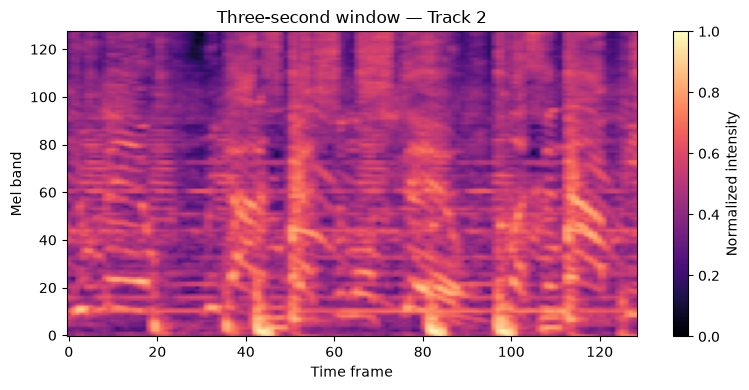

In [8]:
# Define the relevant model configs for model experiment pulling in full resolution spectrograms and splitting into 3 second intervals
sample_rate = 22050
hop_length = 512
window_seconds = 3
window_frames = round(window_seconds * sample_rate / hop_length)  # 129 frames
windows_per_track = 10
mel_dir = LOCAL / 'processed_mel'

def load_mel_window(track_id, start_frame=None, window_frames=129, rng=None):
    """Load one normalized (128, window_frames, 1) window from a full-res .npy spectrogram."""
    mel = np.load(mel_dir / f'{int(track_id):06d}.npy')
    max_start = mel.shape[1] - window_frames

    if start_frame is None:
        start_frame = int(rng.integers(0, max_start + 1))

    window = mel[:, start_frame:start_frame + window_frames]
    window = (np.clip(window, -80.0, 0.0) + 80.0) / 80.0
    return np.expand_dims(window, axis=-1).astype(np.float32)

# Preview one random 3-second window
rng_preview = np.random.default_rng(SEED)
sample_id = tables['train'].index[0]
sample_window = load_mel_window(sample_id, start_frame=125, window_frames=window_frames)
print('Window shape:', sample_window.shape, '| Range:', round(float(sample_window.min()), 3), 'to', round(float(sample_window.max()), 3))

plt.figure(figsize=(8, 4))
plt.imshow(sample_window[:, :, 0], origin='lower', aspect='auto', cmap='magma', vmin=0, vmax=1)
plt.title(f'Three-second window — Track {sample_id}')
plt.xlabel('Time frame')
plt.ylabel('Mel band')
plt.colorbar(label='Normalized intensity')
plt.tight_layout()
plt.show()

In [9]:
def make_window_train_dataset(batch_size=32):
    """Yield shuffled batches with one random 3-second window per track per epoch."""
    train_rows = tables['train']
    rng = np.random.default_rng(SEED)

    def examples():
        order = rng.permutation(len(train_rows))
        for idx in order:
            track_id = train_rows.index[idx]
            label = int(train_rows.iloc[idx]['genre_id'])
            window = load_mel_window(track_id, start_frame=None, window_frames=window_frames, rng=rng)
            yield window, label

    dataset = tf.data.Dataset.from_generator(
        examples,
        output_signature=(
            tf.TensorSpec(shape=(128, window_frames, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.int64)
        )
    )
    return dataset.batch(batch_size).prefetch(1)


def make_fixed_window_dataset(split='val', batch_size=32, windows_per_track=10):
    """Yield evenly spaced 3-second windows across each track for evaluation."""
    split_rows = tables[split]
    # All processed tracks have 1,292 frames
    start_frames = np.linspace(0, 1292 - window_frames, num=windows_per_track).round().astype(int)

    def examples():
        for track_id, row in split_rows.iterrows():
            mel = np.load(mel_dir / f'{int(track_id):06d}.npy')
            for start in start_frames:
                window = mel[:, start:start + window_frames]
                window = (np.clip(window, -80.0, 0.0) + 80.0) / 80.0
                yield np.expand_dims(window, axis=-1).astype(np.float32), int(row['genre_id'])

    dataset = tf.data.Dataset.from_generator(
        examples,
        output_signature=(
            tf.TensorSpec(shape=(128, window_frames, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.int64)
        )
    )
    return dataset.batch(batch_size).prefetch(1)


def score_window_model(model, dataset, split='val', windows_per_track=10):
    """Average predicted probabilities across windows to get one prediction per track."""
    y_true = tables[split]['genre_id'].to_numpy()
    window_logits = model.predict(dataset, verbose=0)
    window_probs = tf.nn.softmax(window_logits, axis=1).numpy()

    track_probs = window_probs.reshape(len(y_true), windows_per_track, N_CLASSES).mean(axis=1)
    y_pred = track_probs.argmax(axis=1)

    metrics = {
        'acc': accuracy_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred, labels=list(range(N_CLASSES)), average='macro')
    }
    return metrics, y_pred

In [10]:
batch_size = 32
window_train_data = make_window_train_dataset(batch_size=batch_size)
window_val_data = make_fixed_window_dataset(split='val', batch_size=batch_size, windows_per_track=windows_per_track)

window_model = build_model(
    learning_rate=0.001,
    dropout=0.3,
    l2=0.0001,
    input_shape=(128, window_frames, 1)
)
print('Window model input shape:', window_model.input_shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=0.000001, verbose=1
)

window_history = window_model.fit(
    window_train_data,
    validation_data=window_val_data,
    epochs=MAX_EPOCHS,
    shuffle=False,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# Evaluate train and validation at the track level (averaging 10 windows per track)
window_train_eval = make_fixed_window_dataset(split='train', batch_size=batch_size, windows_per_track=windows_per_track)
window_train_metrics, _ = score_window_model(window_model, window_train_eval, split='train', windows_per_track=windows_per_track)
window_val_metrics, window_val_pred = score_window_model(window_model, window_val_data, split='val', windows_per_track=windows_per_track)

results.append({
    'model': 'resnet18_windows_trial_03',
    'learning_rate': 0.001,
    'batch_size': batch_size,
    'dropout': 0.3,
    'l2': 0.0001,
    'train_acc': window_train_metrics['acc'],
    'train_f1': window_train_metrics['f1'],
    'val_acc': window_val_metrics['acc'],
    'val_f1': window_val_metrics['f1'],
    'gap': window_train_metrics['acc'] - window_val_metrics['acc'],
    'best_epoch': int(np.argmin(window_history.history['val_loss'])) + 1
})

win_hist_df = pd.DataFrame(window_history.history)
win_hist_df['epoch'] = np.arange(1, len(win_hist_df) + 1)
histories['resnet18_windows_trial_03'] = win_hist_df

Window model input shape: (None, 128, 129, 1)
Epoch 1/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 83s 406ms/step - accuracy: 0.3252 - loss: 2.9551 - val_accuracy: 0.1702 - val_loss: 5.6213 - learning_rate: 0.0010
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 81s 404ms/step - accuracy: 0.4050 - loss: 2.5837 - val_accuracy: 0.1684 - val_loss: 3.6414 - learning_rate: 0.0010
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 81s 408ms/step - accuracy: 0.4481 - loss: 2.3681 - val_accuracy: 0.3584 - val_loss: 2.6608 - learning_rate: 0.0010
Epoch 4/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 81s 404ms/step - accuracy: 0.4621 - loss: 2.2168 - val_accuracy: 0.3487 - val_loss: 2.5778 - learning_rate: 0.0010
Epoch 5/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 80s 403ms/step - accuracy: 0.4816 - loss: 2.0834 - val_accuracy: 0.2005 - val_loss: 3.2182 - learning_rate: 0.0010
Epoch 6/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 81s 405ms/step - accuracy: 0.4980 - loss: 1.9701 - val_accuracy: 0.4144 - val_loss: 2.0496 - learning_rate: 0.0010
Epoch 7/40
200/200 ━━━━━

### Step 6: Model Comparison, Learning Curves, and Validation Evals
Will review the results and learning curves of all models experimented with. Creating a confusion matrix with the model selected.

,model,learning_rate,batch_size,dropout,l2,train_acc,train_f1,val_acc,val_f1,gap,best_epoch
0,resnet18_windows_trial_03,0.0010,32,0.3,0.00010,0.730956,0.727789,0.57000,0.560742,0.160956,23
1,resnet18_trial_00,0.0010,32,0.3,0.00010,0.524323,0.502962,0.38375,0.354913,0.140573,14
2,resnet18_trial_02,0.0001,32,0.3,0.00010,0.620679,0.604205,0.39125,0.348956,0.229429,3
3,resnet18_trial_01,0.0010,32,0.5,0.00001,0.352104,0.356338,0.28750,0.285752,0.064604,6


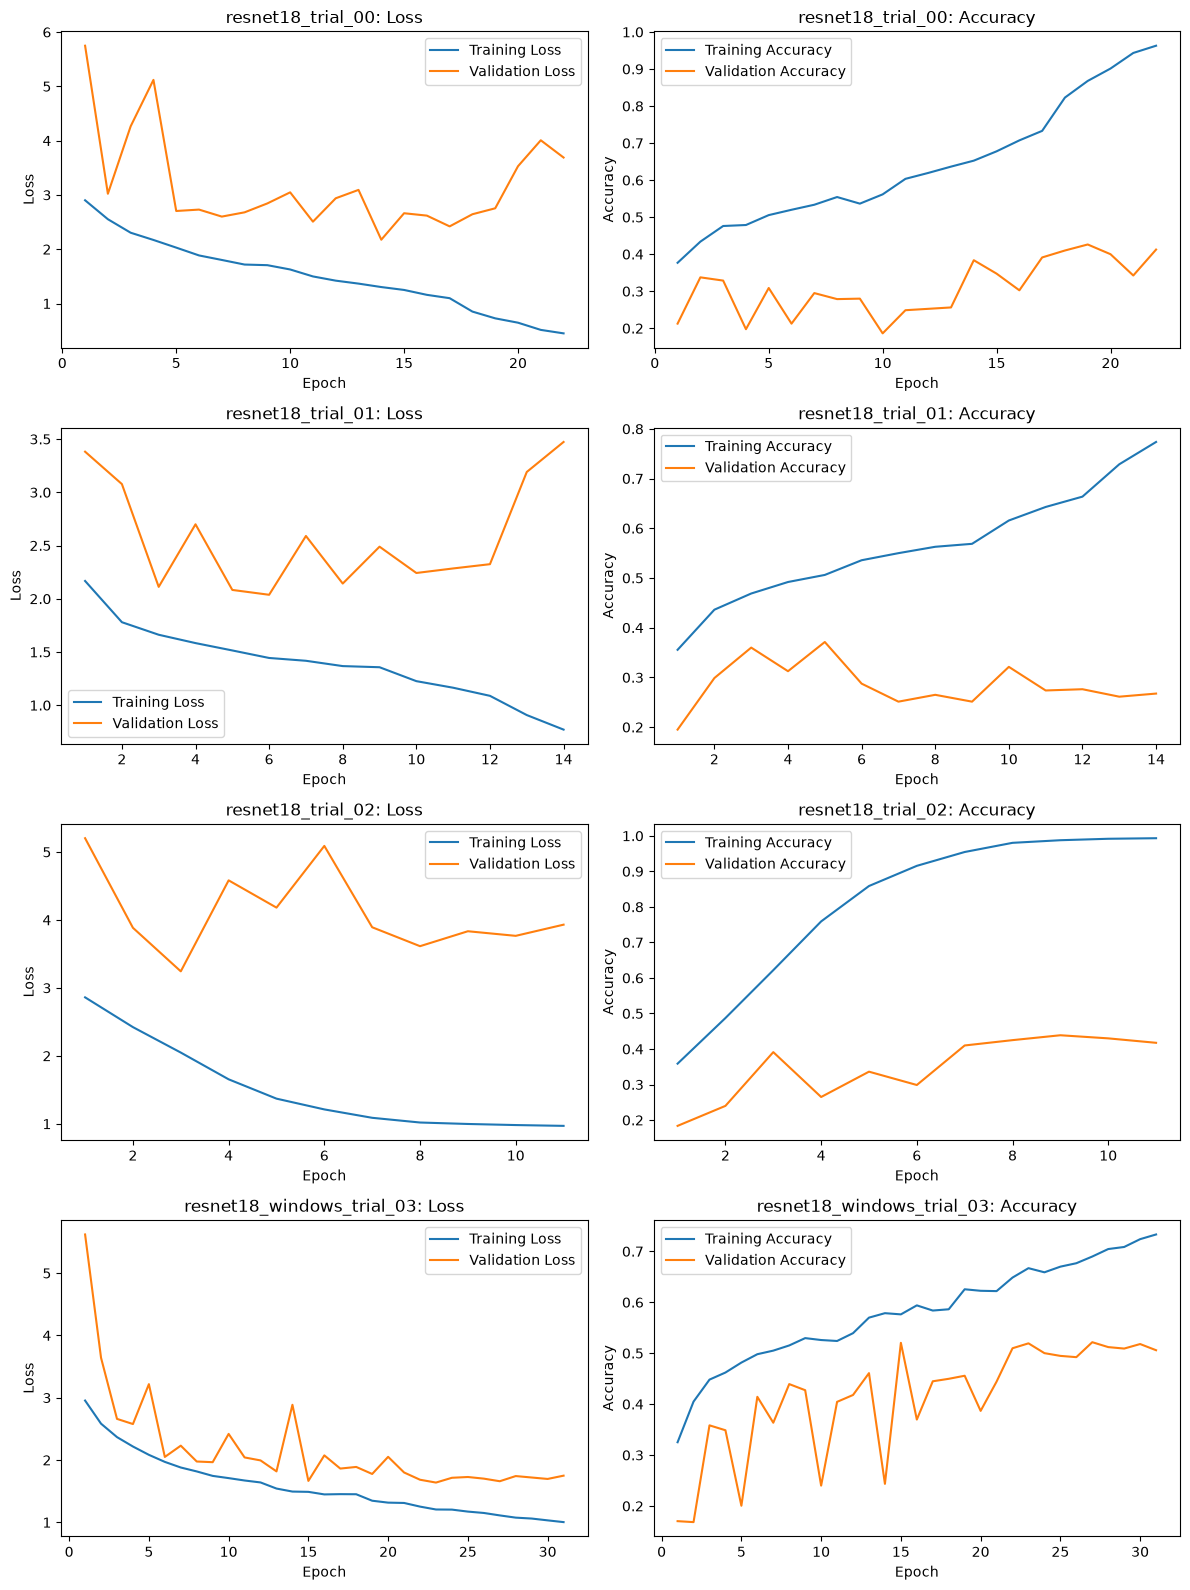

In [11]:
# Create a comparison table to review the results of all experiments
comparison = pd.DataFrame(results).sort_values('val_f1', ascending=False).reset_index(drop=True)
display(comparison)

# Plot the training and validation curves for each experiment
fig, axes = plt.subplots(len(histories), 2, figsize=(12, 4 * len(histories)))
if len(histories) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (name, history) in enumerate(histories.items()):
    axes[row, 0].plot(history['epoch'], history['loss'], label='Training Loss')
    axes[row, 0].plot(history['epoch'], history['val_loss'], label='Validation Loss')
    axes[row, 0].set_title(f'{name}: Loss')
    axes[row, 0].set_xlabel('Epoch')
    axes[row, 0].set_ylabel('Loss')
    axes[row, 0].legend()

    axes[row, 1].plot(history['epoch'], history['accuracy'], label='Training Accuracy')
    axes[row, 1].plot(history['epoch'], history['val_accuracy'], label='Validation Accuracy')
    axes[row, 1].set_title(f'{name}: Accuracy')
    axes[row, 1].set_xlabel('Epoch')
    axes[row, 1].set_ylabel('Accuracy')
    axes[row, 1].legend()

plt.tight_layout()
plt.show()

Selected model: resnet18_windows_trial_03
Val Accuracy: 0.5700 | Val Macro-F1: 0.5607
               precision    recall  f1-score   support

   Electronic      0.557     0.590     0.573       100
 Experimental      0.463     0.690     0.554       100
         Folk      0.736     0.640     0.684       100
      Hip-Hop      0.805     0.620     0.701       100
 Instrumental      0.486     0.540     0.512       100
International      0.552     0.740     0.632       100
          Pop      0.212     0.110     0.145       100
         Rock      0.750     0.630     0.685       100

     accuracy                          0.570       800
    macro avg      0.570     0.570     0.561       800
 weighted avg      0.570     0.570     0.561       800



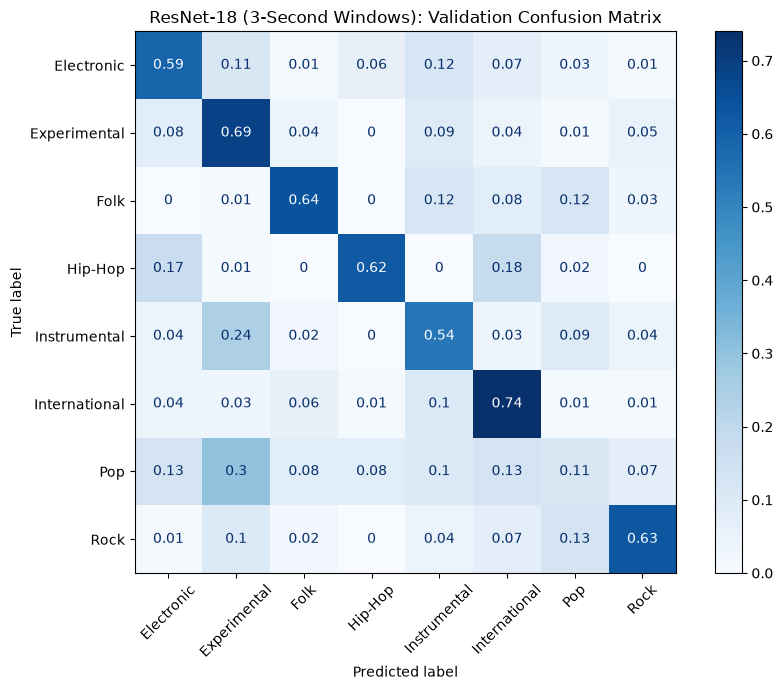

In [12]:
# Print the results and create a confusion matrix for the best-performing model (ResNet-18 with 3-second windows)
print('Selected model: resnet18_windows_trial_03')
print(f"Val Accuracy: {window_val_metrics['acc']:.4f} | Val Macro-F1: {window_val_metrics['f1']:.4f}")
print(classification_report(y_val, window_val_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_val,
    window_val_pred,
    display_labels=class_names,
    normalize='true',
    xticks_rotation=45,
    ax=ax,
    cmap='Blues'
)
ax.set_title('ResNet-18 (3-Second Windows): Validation Confusion Matrix')
plt.tight_layout()
plt.show()

## Results & Interpretation
Parameter tuning of the ResNet-18 Model using the full 30 second spectrogram data resulted in a model with 0.52 training data accuracy, 0.50 training data F1 score, and a 0.38 validation data accuracy (0.14 gap) and a 0.35 validation data F1. The validation-training data accuracy gap of 0.14 suggests overfitting of the model to the training data.

We performed additional ResNet-18 Model experimentation using three-second windows from the original spectrograms instead of the pooled 30-second images (fuller image resolution). During training, we sampled one random window per track each epoch. During validation, we used fixed windows and averaged the predicted probabilities to produce one genre prediction per track.

This resulted in a final model with 0.73 training data accuracy, 0.73 training data F1, 0.57 validation data accuracy, and 0.56 validation data F1. This validation-training data accuracy gap of 0.16 again suggests overfitting of the model to the training data, but shows a much improved validation data accuracy and F1, when compared to the baseline ResNet-18 model and the baseline logistic regression model.

The model performs strongest on Hip-Hop (F1: 0.70), Rock (F1: 0.69), and Folk (F1: 0.68), but by contrast, struggles to accurately predict Pop tracks (F1: 0.15).